In [1]:
import pandas as pd

In [2]:
import datetime as dt
from sklearn.feature_extraction import DictVectorizer

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# import mlflow
# # mlflow.set_tracking_uri("/workspaces/mlops-handson/mlflow.db")
# mlflow.set_tracking_uri("sqlite:////workspaces/mlops-handson/mlflow.db")
import mlflow
from pathlib import Path

db_path = Path.cwd() / "mlflow.db"          # or Path.home() / "mlops-handson" / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{db_path}")
mlflow.set_experiment("Mlops-handson")

<Experiment: artifact_location='/Users/deepak/mlops/mlops-handson/hands-on1/mlruns/1', creation_time=1792931813615, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1792931813615, lifecycle_stage='active', name='Mlops-handson', tags={}, trace_location=None, workspace='default'>

In [16]:
# !pip install mlflow

In [18]:
def read_dataframe(filename):
    df = pd.read_parquet(filename)

    df["tpep_pickup_datetime"] = pd.to_datetime(df["tpep_pickup_datetime"])
    df["tpep_dropoff_datetime"] = pd.to_datetime(df["tpep_dropoff_datetime"])

    df["duration"] = (df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]).dt.total_seconds() / 60

    df = df[(df["duration"] >= 1) & (df["duration"] <= 60)].copy()

    categorical = ["PULocationID", "DOLocationID"]
    df[categorical] = df[categorical].astype(str)

    df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

    return df

In [19]:
# train_df = inferance(train_df)
train_df = read_dataframe('data/yellow_tripdata_2021-02.parquet')


In [20]:
# train_df
val_df = read_dataframe('data/yellow_tripdata_2021-02.parquet')


In [21]:
categorical = ["PU_DO"]
numerical = ['trip_distance']


# categorical_value = ['PULocationID','DOLocationID']
# numerical = ['trip_distance']
# train_df[categorical_value] = train_df[categorical_value].astype(str)

# train_df['PU_DO'] = train_df['PULocationID'] + '_' + train_df['DOLocationID']

# categorical = ['PU_DO'] 
# numerical = ['trip_distance']

train_dicts = train_df[categorical+numerical].to_dict(orient = 'records')
dv = DictVectorizer()

X_train = dv.fit_transform(train_dicts)

target = 'duration'

Y_train = train_df[target].values


In [22]:
categorical = ["PU_DO"]
numerical = ['trip_distance']

# val_df[categorical_value] = val_df[categorical_value].astype(str)

# val_df ['PU_DO'] = val_df ['PULocationID'] + '_' + val_df ['DOLocationID']
val_dicts = val_df[categorical+numerical].to_dict(orient = 'records')
# dv = DictVectorizer()

X_val = dv.transform(val_dicts)
Y_val = val_df[target].values

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error
with mlflow.start_run():
    mlflow.set_tag("model","LinearRegression")
    mlflow.log_param("train_data_path","data/yellow_tripdata_2021-01.parquet")
    mlflow.log_param("valid_data_path","data/yellow_tripdata_2021-02.parquet")
    model = LinearRegression()
    
    model.fit(X_train,Y_train)
    y_pred = model.predict(X_val)
    rmse = root_mean_squared_error(Y_val,y_pred)
    mlflow.log_metric("rmse",rmse)
    mlflow.log_artifact(local_path="models/lin_reg.bin", artifact_path="models_pickle")
    

In [24]:
y_pred = model.predict(X_val)

In [25]:
rmse = root_mean_squared_error(Y_val,y_pred)

In [26]:
rmse

4.741901598865586

/var/folders/9c/d6zs_wyd2114b01msmt1jdrw0000gn/T/ipykernel_94949/4293836138.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(y_pred, label='prediction')
/var/folders/9c/d6zs_wyd2114b01msmt1jdrw0000gn/T/ipykernel_94949/4293836138.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(Y_val, label

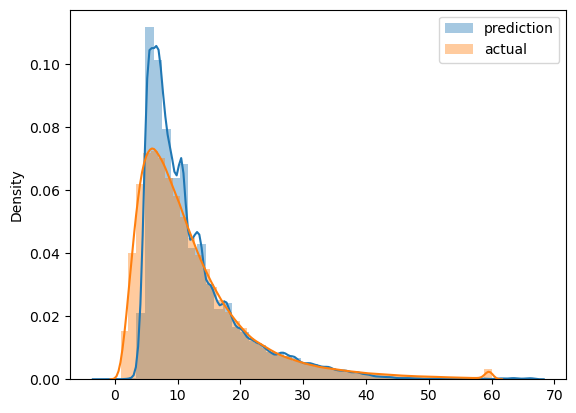

In [27]:
sns.distplot(y_pred, label='prediction')
sns.distplot(Y_val, label='actual')

plt.legend()

In [22]:
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge

In [11]:
import numpy as np
from scipy import sparse

def to_int32(X):
    X = sparse.csc_matrix(X)          # Lasso works on CSC internally
    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)
    return X

X_train = to_int32(X_train)
X_val = to_int32(X_val)



lr = Lasso(0.01)
lr.fit(X_train, Y_train)

y_pred = lr.predict(X_val)

root_mean_squared_error(Y_val, y_pred)

KeyboardInterrupt: 

In [16]:
import pickle

In [28]:
with open('models/lin_reg.bin', 'wb') as f_out:
    pickle.dump((dv, model), f_out)

In [ ]:
!pip install hyperopt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 973.5/973.5 kB 15.5 MB/s eta 0:00:00


In [ ]:
!pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 8.8 MB/s eta 0:00:00a 0:00:01


In [24]:
import xgboost as xgb

In [25]:
from hyperopt import fmin, tpe, hp, STATUS_OK, Trials
from hyperopt.pyll import scope
from sklearn.metrics import root_mean_squared_error

In [26]:
train  = xgb.DMatrix(X_train, label = Y_train)
val = xgb.DMatrix(X_val, label = Y_val)

In [ ]:
def objective(params):
    with mlflow.start_run():
        mlflow.set_tag("models", "xgboost")
        mlflow.log_params(params)
        
        boost = xgb.train(
            params=params,
            dtrain=train,
            num_boost_round=1000,
            evals=[(val, 'validation')],  # Fixed: list containing the tuple
            early_stopping_rounds=50,
            verbose_eval=False            # Optional: keeps notebook output clean across 50 trials
        )
        
        y_pred = boost.predict(val)
        rmse = root_mean_squared_error(Y_val, y_pred)
        mlflow.log_metric("rmse", rmse)
        
    return {'loss': rmse, 'status': STATUS_OK}
        

In [ ]:
search_space = {
    'max_depth': scope.int(hp.quniform('max_depth', 4, 100, 1)),
    'learning_rate': hp.loguniform('learning_rate', -3, 0),
    'reg_alpha': hp.loguniform('reg_alpha', -5, -1),
    'reg_lambda': hp.loguniform('reg_lambda', -6, -1),
    'min_child_weight': hp.loguniform('min_child_weight', -1, 3),
    'objective': 'reg:linear',
    'seed': 42
}

best_result = fmin(
    fn = objective,
    space = search_space,
    algo = tpe.suggest,
    max_evals = 50,
    trials = Trials()
)

  0%|                                                                                             | 0/50 [00:00<?, ?trial/s, best loss=?]

/home/codespace/anaconda3/lib/python3.14/site-packages/xgboost/callback.py:385: UserWarning: [12:19:14] WARNING: /__w/xgboost/xgboost/src/objective/regression_obj.cu:275: reg:linear is now deprecated in favor of reg:squarederror.
  self.starting_round = model.num_boosted_rounds()



  2%|█▎                                                              | 1/50 [03:45<3:04:32, 225.97s/trial, best loss: 3.9059046100560955]

/home/codespace/anaconda3/lib/python3.14/site-packages/xgboost/callback.py:385: UserWarning: [12:22:59] WARNING: /__w/xgboost/xgboost/src/objective/regression_obj.cu:275: reg:linear is now deprecated in favor of reg:squarederror.
  self.starting_round = model.num_boosted_rounds()



In [ ]:
# params = {'learning_rate':0.6879794592819034,
# 'max_depth':6,
# 'min_child_weight':6.937305288360974,
# 'reg_alpha':0.012669613705483586,
# 'reg_lambda':0.029694554429786836,
# 'seed':42
# }
# mlflow.xgboost.autolog()

# with mlflow.start_run():
#     mlflow.log_param("train_data_path","data/yellow_tripdata_2021-01.parquet")
#     mlflow.log_param("valid_data_path","data/yellow_tripdata_2021-02.parquet")
#     # mlflow.log_artifact("models/preprocessor.b", artifact_path="preprocessor")
#     boost = xgb.train(
#             params=params,
#             dtrain=train,
#             num_boost_round=1000,
#             evals=[(val, 'validation')],  # Fixed: list containing the tuple
#             early_stopping_rounds=50,
#             verbose_eval=False            # Optional: keeps notebook output clean across 50 trials
#         )
#     y_pred = boost.predict(val)
#     rmse = root_mean_squared_error(Y_val, y_pred)
#     mlflow.log_metric("rmse", rmse)
    
    


2026/10/25 18:09:33 WARNING mlflow.xgboost: Failed to infer model signature: could not sample data to infer model signature: please ensure that autologging is enabled before constructing the dataset.
2026/10/25 18:09:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


In [ ]:
# import pickle
# from pathlib import Path

# import mlflow
# import mlflow.xgboost
# import numpy as np
# import xgboost as xgb
from mlflow.models import infer_signature
# from sklearn.metrics import root_mean_squared_error

# 1. Tracking setup (use a path that exists on your machine)
db_path = Path.cwd() / "mlflow.db"
mlflow.set_tracking_uri(f"sqlite:///{db_path}")
mlflow.set_experiment("Mlops-handson")

# 2. Autolog before anything else. log_models=False because we log the model
#    ourselves below with a proper signature, so there's no duplicate copy.
mlflow.xgboost.autolog(log_models=True)

# 3. Build the DMatrix objects
train = xgb.DMatrix(X_train, label=Y_train)
val = xgb.DMatrix(X_val, label=Y_val)

params = {
    "learning_rate": 0.6879794592819034,
    "max_depth": 6,
    "min_child_weight": 6.937305288360974,
    "reg_alpha": 0.012669613705483586,
    "reg_lambda": 0.029694554429786836,
    "objective": "reg:squarederror",
    "seed": 42,
}

with mlflow.start_run():
    mlflow.log_param("train_data_path", "data/yellow_tripdata_2021-01.parquet")
    mlflow.log_param("valid_data_path", "data/yellow_tripdata_2021-02.parquet")

    boost = xgb.train(
        params=params,
        dtrain=train,
        num_boost_round=1000,
        evals=[(val, "validation")],
        early_stopping_rounds=50,
        verbose_eval=False,
    )

    y_pred = boost.predict(val)
    rmse = root_mean_squared_error(Y_val, y_pred)
    mlflow.log_metric("rmse", rmse)

    # 4. Log the preprocessor (replace `dv` with your DictVectorizer variable)
    Path("models").mkdir(exist_ok=True)
    with open("models/preprocessor.b", "wb") as f:
        pickle.dump(dv, f)
    mlflow.log_artifact("models/preprocessor.b", artifact_path="preprocessor")

    # 5. Log the model with an explicit signature and input example
    n = 5
    X_sample = X_val[:n]
    X_sample = X_sample.toarray() if hasattr(X_sample, "toarray") else np.asarray(X_sample)
    signature = infer_signature(X_sample, boost.predict(xgb.DMatrix(X_sample)))

    mlflow.xgboost.log_model(
        boost,
        name="model",
        signature=signature,
        input_example=X_sample,
    )

print(f"RMSE: {rmse:.4f}")

2026/10/25 18:22:16 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


RMSE: 3.9059


In [ ]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.svm import LinearSVR

mlflow.sklearn.autolog()

for model_class in (RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor, LinearSVR):

    with mlflow.start_run():

        mlflow.log_param("train_data_path","data/yellow_tripdata_2021-01.parquet")
        mlflow.log_param("valid_data_path","data/yellow_tripdata_2021-02.parquet")
        mlflow.log_artifact("models/preprocessor.b", artifact_path="preprocessor")

        mlmodel = model_class()
        mlmodel.fit(X_train, Y_train)

        y_pred = mlmodel.predict(X_val)
        rmse = root_mean_squared_error(Y_val, y_pred, squared=False)
        mlflow.log_metric("rmse", rmse)

2026/10/26 15:51:12 WARNING mlflow.utils.autologging_utils: MLflow sklearn autologging is known to be compatible with 1.6.0 <= scikit-learn, but the installed version is 1.5.1. If you encounter errors during autologging, try upgrading / downgrading scikit-learn to a compatible version, or try upgrading MLflow.


In [27]:
import time
import numpy as np
import mlflow
import mlflow.sklearn
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.svm import LinearSVR
from sklearn.metrics import root_mean_squared_error

# Don't pickle huge models or score the train set after every fit
mlflow.sklearn.autolog(log_models=False, log_datasets=False,
                       log_post_training_metrics=False)

# Train on a subsample for quick model comparison
N = 200_000
rng = np.random.default_rng(42)
idx = rng.choice(X_train.shape[0], size=min(N, X_train.shape[0]), replace=False)
X_tr, y_tr = X_train[idx], np.asarray(Y_train)[idx]

models = {
    "RandomForest": RandomForestRegressor(n_estimators=30, max_depth=12,
                                          min_samples_leaf=5, n_jobs=-1, random_state=42),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=30, max_depth=12,
                                      min_samples_leaf=5, n_jobs=-1, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, max_depth=4,
                                                  subsample=0.5, random_state=42),
    "LinearSVR": LinearSVR(max_iter=1000, random_state=42),
}

for name, mlmodel in models.items():
    with mlflow.start_run(run_name=name):
        mlflow.log_param("train_data_path", "data/yellow_tripdata_2021-01.parquet")
        mlflow.log_param("valid_data_path", "data/yellow_tripdata_2021-02.parquet")
        mlflow.log_param("train_rows", len(y_tr))
        mlflow.log_artifact("models/preprocessor.b", artifact_path="preprocessor")

        t0 = time.time()
        mlmodel.fit(X_tr, y_tr)
        fit_s = time.time() - t0

        y_pred = mlmodel.predict(X_val)
        rmse = root_mean_squared_error(Y_val, y_pred)

        mlflow.log_metric("rmse", rmse)
        mlflow.log_metric("fit_seconds", fit_s)
        print(f"{name}: rmse={rmse:.3f}  fit={fit_s:.0f}s")

2026/10/26 17:16:28 WARNING mlflow.utils.autologging_utils: MLflow sklearn autologging is known to be compatible with 1.6.0 <= scikit-learn, but the installed version is 1.5.1. If you encounter errors during autologging, try upgrading / downgrading scikit-learn to a compatible version, or try upgrading MLflow.


RandomForest: rmse=4.493  fit=2s
ExtraTrees: rmse=8.160  fit=1s
GradientBoosting: rmse=4.473  fit=5s


/opt/anaconda3/lib/python3.12/site-packages/sklearn/svm/_base.py:1235: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


LinearSVR: rmse=1199.114  fit=4s


In [29]:
from mlflow.tracking import MlflowClient

client = MlflowClient()

exp = client.get_experiment_by_name("Mlops-handson")

best = client.search_runs(
    [exp.experiment_id], order_by = ["metrics.rmse ASC"],max_results = 1
)[0]


mv = mlflow.register_model(f"runs/:{best.info.run_id}/model","nyc-taxi-duration")

print(mv.name,mv.version)

nyc-taxi-duration 1


Successfully registered model 'nyc-taxi-duration'.
Created version '1' of model 'nyc-taxi-duration'.


In [30]:
client.set_registered_model_alias("nyc-taxi-duration","champion",mv.version)